# Анализ рынка общепита Москвы: выявление успешных концепций и локаций для нового бизнеса


### Цели и задачи проекта

**Цель проекта** — на основе открытых данных о заведениях общественного питания Москвы понять, какие форматы и районы могут быть более перспективными для открытия нового заведения.

В этом проекте я исследую рынок заведений общественного питания Москвы. Задача похожа на реальную консалтинговую: нужно помочь принять решение об открытии нового заведения не на основе интуиции, а на основе данных — о категориях, районах, рейтингах, ценах и посадочных местах.

**Задачи:**

1. Познакомиться с двумя датасетами: информацией о заведениях и данными о ценах.
2. Проверить качество данных и провести предобработку: разобраться с пропусками, дубликатами и типами данных.
3. Исследовать структуру рынка Москвы:
   - какие категории заведений представлены и как они распределены по районам;
   - как отличаются заведения по рейтингу, количеству мест, ценовой категории и среднему чеку;
   - какую долю рынка занимают сетевые заведения.
4. Сопоставить полученные результаты и сформулировать рекомендации: какие форматы заведений и районы могут быть более перспективными для открытия нового проекта.

### Описание данных

Для анализа поступили данные о заведениях общественного питания Москвы. Данные состоят из двух датасетов:

- `rest_info.csv` — информация о заведениях;  
- `rest_price.csv` — информация о ценах в заведениях.  

**Описание датасета** `rest_info`

- `name` — название заведения;  
- `address` — адрес заведения;  
- `district` — административный район;  
- `category` — категория заведения (кафе, ресторан, пиццерия и т.д.);  
- `hours` — время работы;  
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс.Картах (макс. 5.0);  
- `chain` — признак сетевого заведения (0 — не сетевое, 1 — сетевое);  
- `seats` — количество посадочных мест.  

**Описание датасета** `rest_price`

- `price` — ценовая категория заведения (низкая, средняя, высокая и т.д.);  
- `avg_bill` — средняя стоимость заказа в виде строки с диапазоном;  
- `middle_avg_bill` — числовая оценка среднего чека (только для значений `Средний счёт`);  
- `middle_coffee_cup` — числовая оценка стоимости одной чашки капучино.


### Содержимое проекта

- [1. Загрузка данных и знакомство с ними](#1-загрузка-данных-и-знакомство-с-ними)
- [2. Предобработка данных](#2-предобработка-данных)
- [3. Исследовательский анализ данных](#3-исследовательский-анализ-данных)
  - [3.1. Анализ категорий заведений](#31-анализ-категорий-заведений)
  - [3.2. Распределение заведений по административным округам](#32-распределение-заведений-по-административным-округам)
  - [3.3. Анализ заведений Центрального административного округа](#33-анализ-заведений-центрального-административного-округа)
  - [3.9. Промежуточный вывод](#39-промежуточный-вывод)
- [4. Итоговый вывод и рекомендации](#4-итоговый-вывод-и-рекомендации)


##  Загрузка данных и знакомство с ними


In [1]:
# Установка библиотеки phik в "тихом" режиме (-q), чтобы не засорять вывод логами зависимосте
!pip install phik -q

In [2]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

warnings.filterwarnings("ignore")  # бережем глаза от ненужных предупреждений

In [3]:
# Выгружаем данные в переменные bank_df и clients_df
resinfo_df = pd.read_csv('/Users/sonechka/Documents/данные/data1/rest_info.csv')
resprice_df = pd.read_csv('/Users/sonechka/Documents/данные/data1/rest_price.csv')

- Познакомьтесь с данными и изучим общую информацию о них.

Познакомимся с данными датасета `rest_info.csv` — выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [4]:
# Выводим первые строки датафрейма на экран
resinfo_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
# Выводим информацию о датафрейме
resinfo_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Теперь познакомимся с данными датасета `rest_price.csv` таким же образом:

In [6]:
# Выводим первые строки датафрейма на экран
resprice_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
# Выводим информацию о датафрейме
resprice_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


---

### Промежуточный вывод


1. **Объём данных**:  
- `rest_info.csv` содержит 8406 строк и 9 столбцов;  
- `rest_price.csv` содержит 4058 строк и 5 столбцов.  

2. **Соответствие описанию**:  
- Все столбцы соответствуют документации;  
- Типы данных в целом верные: строковые (`object`) для текстовых данных, числовые (`float64`, `int64`) для рейтингов, количества мест и средних чеков; для анализа понизим тип данных в двух столбцах для экономии памяти: rating — перевести с float64 на float32, chain — перевести с int64 на int8. 
- Названия столбцов записаны в **snake_case**, что нас устраивает, и приводить их к одному виду не требуется.  

3. **Пропущенные значения**:  
- В `rest_info` есть пропуски в столбцах `hours` (536 значений) и `seats` (3611 значений);  
- В `rest_price` пропуски встречаются в `price` (743), `avg_bill` (242), `middle_avg_bill` (909) и `middle_coffee_cup` (3523);  
- Пропуски нужно будет обработать или учесть при анализе.  

4. **Особенности данных**:  
- Столбец `hours` содержит текстовую информацию с разным форматом (например, “ежедневно, 10:00–22:00” и диапазоны по дням недели), что потребует нормализации для анализа режима работы;  
- Столбец `seats` имеет пропуски и возможные выбросы (например, очень большое или маленькое количество мест);  
- В `rest_price` столбцы `middle_avg_bill` и `middle_coffee_cup` частично заполнены, что ограничит возможность прямого сравнения цен для всех заведений;  
- Не все заведения из `rest_info` есть в `rest_price`, поэтому для объединения датасетов потребуется учитывать пересечение по `id`.


### Подготовка единого датафрейма

- Объединим данные двух датасетов в один, с которым мы и продолжим работу.

In [8]:
# Объединяем данные двух датафреймов по столбцу 'id'
# Тип объединения — left join, чтобы сохранить все заведения из rest_info
rest_df = pd.merge(
    resinfo_df,
    resprice_df,
    on='id',
    how='left'  # все заведения из rest_info, цены при отсутствии будут NaN
)


In [9]:
# Проверим результат
rest_df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


In [10]:
rest_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 853.9+ KB


Объединенный датафрейм: 8 406 заведений, 13 признаков

Ключевые моменты:

Полные данные по названиям, категориям, адресам и рейтингам

Значительные пропуски в ценовых данных (61-94%)

43% пропусков по количеству посадочных мест

Время работы указано для 94% заведений

Для анализа: Данные готовы к исследованию, но анализ цен и посадочных мест будет ограничен из-за пропусков.

##  Предобработка данных

- Текстовые столбцы корректны;

- Числовые столбцы тоже корректны, но для для экономии памяти rating переведем с float64 на float32, chain переведем с int64 на int8.

In [11]:
# Столбец рейтинга переводим с float64 → float32
rest_df['rating'] = resinfo_df['rating'].astype('float32')

In [12]:
# Столбец сетевого признака переводим с int64 → int8
rest_df['chain'] = resinfo_df['chain'].astype('int8')

In [13]:
# Проверим изменения типов данных
rest_df.dtypes

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float32
chain                   int8
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
dtype: object

* Изучим пропуски в данных: посчитаем их количество по столбцам, проанализируем характер пропущенных значений и выдвинем гипотезы о причинах их возникновения. На основе этого определим стратегию обработки - замену на специфичные значения, удаление строк или сохранение пропусков.

In [14]:
# Посчитаем количество пропусков
rest_df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [15]:
# Подсчитываем долю строк с пропусками
rest_df.isna().sum() / rest_df.shape[0]

id                   0.000000
name                 0.000000
category             0.000000
address              0.000000
district             0.000000
hours                0.063764
rating               0.000000
chain                0.000000
seats                0.429574
price                0.605639
avg_bill             0.546039
middle_avg_bill      0.625387
middle_coffee_cup    0.936355
dtype: float64

В объединённом датафрейме `rest_df` наблюдается различное количество пропусков в столбцах. Наибольшая доля пропусков зафиксирована в переменных, связанных с ценовой информацией (`price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`) — от **55% до 93%**. Также присутствуют пропуски в столбцах `hours` (**6%**) и `seats` (**43%**).

**Принятое решение по обработке пропусков:**

* **`seats`** — если в этом столбце **нет нулевых значений**, то пропуски заменим на **–1**.
  Это позволит сохранить все строки, а отрицательное значение будет обозначать отсутствие информации о количестве посадочных мест.
* **Остальные столбцы с пропусками** (`hours`, `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`) **оставляем без изменений**.
  Причины:
  
  * в `hours` незначительное количество пропусков, что не исказит аналитику; 
  * пропуски в остальных столбцах, скорее всего, связаны с отсутствием данных о ценах или времени работы;
  * заполнение их медианой или средним исказит распределение;
  * в дальнейшем такие значения можно будет исключить точечно при анализе определённых метрик.

Таким образом, данные сохраняются максимально полными и корректными для дальнейшего исследования.


In [16]:
# Проверяем наличие нулевых значений в столбце seats
zero_count = (rest_df['seats'] == 0).sum()
print(f"Количество нулевых значений в seats: {zero_count}")


Количество нулевых значений в seats: 136


Так как нулевые значения присутствуют в столбце `seats`, это означает, что пропуски не связаны с отсутствием посадочных мест. Следовательно, пропуски в этом столбце заменим на **–1**, чтобы обозначить отсутствие информации о количестве мест:

In [17]:
rest_df['seats'].fillna(-1, inplace=True)

- Для обеспечения качества данных проведем проверку на явные и неявные дубликаты. Особое внимание уделим комбинации названия и адреса заведения, так как одинаковые названия могут встречаться в разных локациях (сетевые заведения), а одинаковые адреса должны содержать уникальные заведения.

- Для оптимизации поиска дубликатов нормализуем текстовые данные: приведем названия заведений и адреса к единому формату, удалим лишние пробелы и приведем к нижнему регистру. Это поможет выявить неявные дубликаты, вызванные разным написанием одних и тех же значений.

In [18]:
# Приводим названия заведений и адреса к единому формату
rest_df['name'] = rest_df['name'].str.strip().str.lower()
rest_df['address'] = rest_df['address'].str.strip().str.lower()

In [19]:
# Проверяем явные дубликаты
rest_df.duplicated().sum()

np.int64(0)

In [20]:
# Проверяем дубликаты по названию и адресу
rest_df.duplicated(subset=['name', 'address']).sum()

np.int64(4)

In [21]:
# Смотрим все строки, которые дублируются по name и address
duplicates = rest_df[rest_df.duplicated(subset=['name', 'address'], keep=False)]
print(duplicates)


                                    id                       name  category  \
189   072032ce16dc47bfbc63b672c75bd371                       кафе      кафе   
215   897ddbc6746c4388b19dc8a9fcdbb488                       кафе      кафе   
1430  62608690e9cc464fbcd980cfd552e334                  more poke  ресторан   
1511  a69f018d5c064873a3b491b0121bc1b4                  more poke  ресторан   
2211  c6ef39ae8a8c483d8f9a6531bc386a2c  раковарня клешни и хвосты  ресторан   
2420  aba1de7ad7d64ac0a3f8684bda29d905  раковарня клешни и хвосты   бар,паб   
3091  3c2a73ea79a04be48858fab3685f2f37            хлеб да выпечка  булочная   
3109  d3116844e4e048f99614eb30be3214e0            хлеб да выпечка      кафе   

                                      address  \
189              москва, парк ангарские пруды   
215              москва, парк ангарские пруды   
1430  москва, волоколамское шоссе, 11, стр. 2   
1511  москва, волоколамское шоссе, 11, стр. 2   
2211               москва, проспект мира, 1

In [22]:
# Удаляем найденные дубликаты
rest_df = rest_df.drop_duplicates(subset=['name', 'address'])


- Для дальнейшей работы создадим столбец `is_24_7` с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:
  - логическое значение `True` — если заведение работает ежедневно и круглосуточно;
  - логическое значение `False` — в противоположном случае.

In [23]:
# Создаем столбец is_24_7
# True, если в hours есть слова 'круглосуточно' или '24/7', иначе False
rest_df['is_24_7'] = (
    rest_df['hours'].str.contains('круглосуточно|24/7', case=False, na=False) &
    rest_df['hours'].str.contains('ежедневно', case=False, na=False)
)


In [24]:
# Посчитаем количество заведений с is_24_7 = True
num_24_7 = rest_df['is_24_7'].sum()
print(f"Количество заведений, работающих круглосуточно: {num_24_7}")


Количество заведений, работающих круглосуточно: 730


In [25]:
# Проверим результат
rest_df[['name', 'hours', 'is_24_7']].head(15)


,name,hours,is_24_7
0,wowфли,"ежедневно, 10:00–22:00",False
1,четыре комнаты,"ежедневно, 10:00–22:00",False
2,хазри,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",False
3,dormouse coffee shop,"ежедневно, 09:00–22:00",False
4,иль марко,"ежедневно, 10:00–22:00",False
5,sergio pizza,"ежедневно, 10:00–23:00",False
6,огни города,пн 15:00–04:00; вт-вс 15:00–05:00,False
7,mr. уголёк,"пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00...",False
8,donna maria,"ежедневно, 10:00–22:00",False
9,готика,"ежедневно, 12:00–00:00",False


---

### Промежуточный вывод

После предобработки данных напишите промежуточный вывод о проведённой работе. Отразите количество или долю отфильтрованных данных, если вы что-то удаляли.

В ходе предобработки объединённого датафрейма `rest_df` с информацией о заведениях общественного питания Москвы были проведены следующие шаги:

1. **Обработка пропусков:**

   * В столбце `seats` (количество посадочных мест) пропуски заменены на **–1**, чтобы обозначить отсутствие информации, при этом нулевые значения в данных уже присутствовали.
   * В остальных столбцах с пропусками (`hours`, `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`) пропуски оставлены без изменений, так как они связаны с отсутствием информации о времени работы или ценах, и заполнение их средними значениями могло бы исказить данные.

2. **Проверка и удаление дубликатов:**

   * Было выявлено **4 дубликата** по комбинации `name` + `address`.
   * Все дубликаты удалены, что позволило сохранить только уникальные записи.


3. **Создание нового столбца:**

   * Добавлен столбец `is_24_7` с логическими значениями `True/False`, который обозначает, работает ли заведение круглосуточно.

Эти действия позволили подготовить датасет к дальнейшему исследовательскому анализу, сохранив целостность данных и обеспечив корректную обработку пропусков.


##  Исследовательский анализ данных

---

### Задача 1

- Исследуем разнообразие заведений общественного питания Москвы, представленных в данных. Проанализируем количество объектов по каждой категории, чтобы определить наиболее и наименее распространенные форматы. Это позволит понять структуру рынка и выявить потенциальные ниши для нового заведения.

- Результаты визуализируем с помощью столбчатой диаграммы, которая наглядно покажет распределение заведений по категориям и поможет сравнить их популярность.

In [26]:
# Посчитаем количество заведений по категориям
category_counts = rest_df['category'].value_counts()
print(category_counts)


category
кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: count, dtype: int64


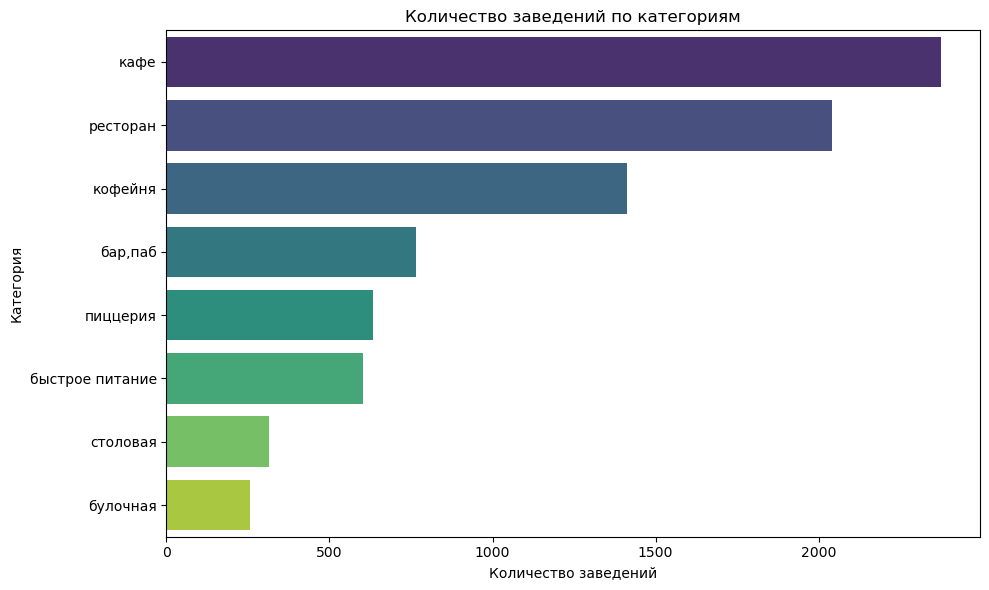

In [27]:
# Построим график
plt.figure(figsize=(10,6))
sns.barplot(x=category_counts.values, y=category_counts.index, palette='viridis')
plt.title('Количество заведений по категориям')
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
plt.tight_layout()
plt.show()


По всему городу Москва наибольшее количество заведений приходится на кафе, рестораны и кофейни. Менее распространённые категории — бары/пабы, пиццерии, быстрое питание, столовые и булочные.

Это говорит о том, что рынок общественного питания в Москве в целом ориентирован на кафе и рестораны, а заведения вроде столовых или булочных встречаются реже.

---

### Задача 2

- Исследуем распределение заведений общественного питания по административным округам Москвы, чтобы выявить наиболее и наименее насыщенные районы. Это поможет определить перспективные локации для открытия нового заведения с учетом уровня конкуренции.

- Отдельно проанализируем структуру заведений в Центральном административном округе - ключевом районе с максимальной концентрацией общепита. Сравним распределение категорий в ЦАО с общей картиной по городу.

- Результаты представим в виде наглядных диаграмм, показывающих плотность заведений по округам и категорийный состав ЦАО.

In [28]:
# Посчитаем количество заведений по административным округам
district_counts = rest_df['district'].value_counts()
print(district_counts)

district
Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: count, dtype: int64


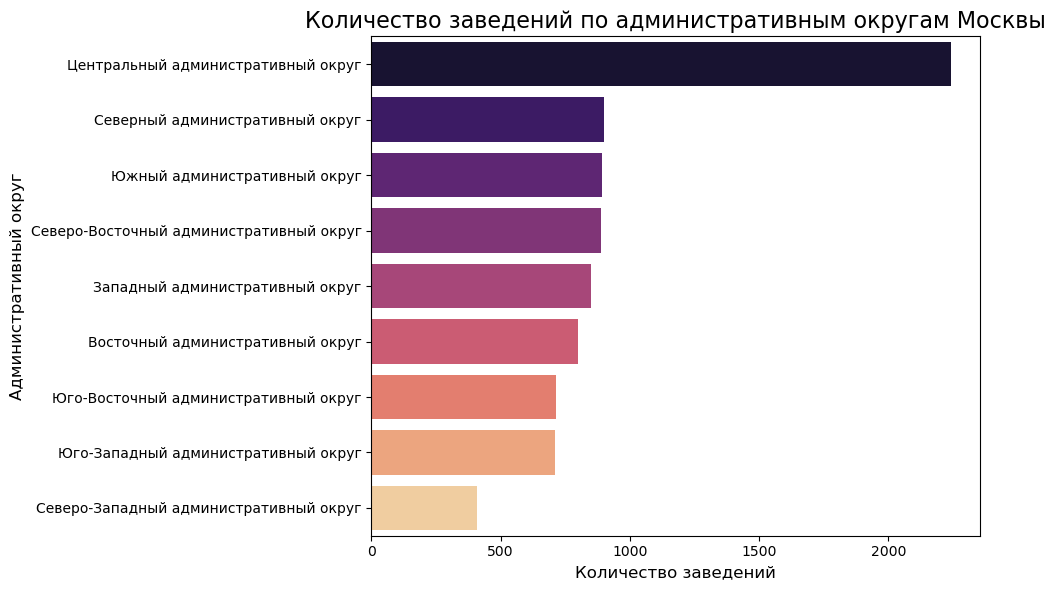

In [29]:
# Построим график
plt.figure(figsize=(10,6))
sns.barplot(x=district_counts.values, y=district_counts.index, palette='magma')
plt.title('Количество заведений по административным округам Москвы', fontsize=16)
plt.xlabel('Количество заведений', fontsize=12)
plt.ylabel('Административный округ', fontsize=12)
plt.tight_layout()
plt.show()


In [30]:
# Фильтрация центра
central = rest_df[rest_df['district'] == 'Центральный административный округ']
# Группировка по категориям
central_cat_counts = central['category'].value_counts().reset_index()
central_cat_counts.columns = ['category', 'count']
print(central_cat_counts)

          category  count
0         ресторан    670
1             кафе    464
2          кофейня    428
3          бар,паб    364
4         пиццерия    113
5  быстрое питание     87
6         столовая     66
7         булочная     50


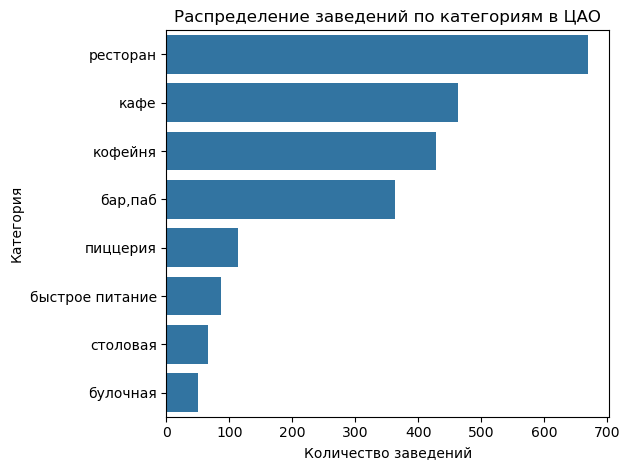

In [31]:
sns.barplot(data=central_cat_counts, x='count', y='category', orient='h')
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
plt.title('Распределение заведений по категориям в ЦАО')
plt.tight_layout()
plt.show()

- Наибольшее количество заведений сосредоточено в **Центральном административном округе**, что объясняется высокой плотностью населения, деловой и туристической активностью. Остальные округа представлены более равномерно, кроме **Северо-Западного административного округа** (409 заведений). 

- В ЦАО явно преобладают рестораны, за ними с заметным отрывом следуют кафе и кофейни. Бары, пиццерии и заведения быстрого питания представлены значительно меньше, а столовые и булочные занимают последние места. Это говорит о том, что гастрономическая сфера округа ориентирована в первую очередь на ресторанный отдых и неформальные встречи в кафе.

- Таким образом, рынок общественного питания Москвы сильно концентрируется в центре города, а удалённые районы имеют меньшее количество заведений.


---

### Задача 3

- Исследуем соотношение сетевых и несетевых заведений общественного питания. Сначала определим, каких заведений больше в целом, а затем проанализируем, в каких категориях сетевой формат встречается чаще всего.
- Для наглядности построим круговую диаграмму для общего распределения и столбчатую диаграмму по долям сетевых заведений в разрезе категорий.

In [32]:
# Считаем количество сетевых (1) и несетевых (0) заведений
chain_counts = rest_df['chain'].value_counts()
print(chain_counts)

chain
0    5199
1    3203
Name: count, dtype: int64


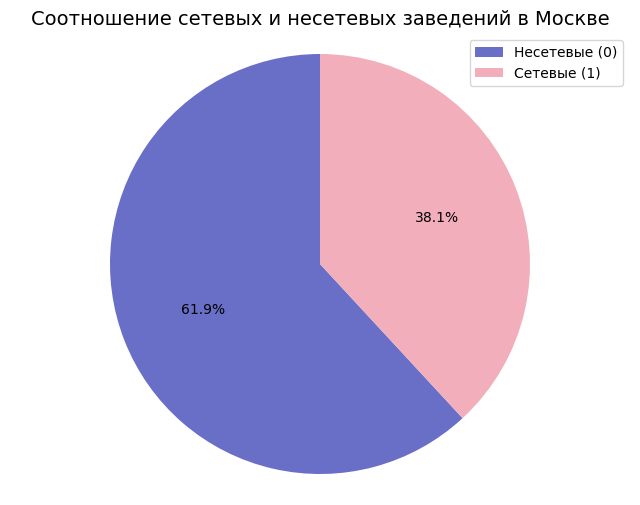

In [33]:
plt.figure(figsize=(8, 6))
patches, texts, autotexts = plt.pie(chain_counts.values, autopct='%1.1f%%', 
                                    colors=['#696FC7','#F2AEBB'], startangle=90)
plt.title('Соотношение сетевых и несетевых заведений в Москве', fontsize=14)
plt.axis('equal')
plt.legend(patches, ['Несетевые (0)', 'Сетевые (1)'], loc='best')
plt.show()

Сначала создадим сводную таблицу (pivot table) для категорий:

In [34]:
# Сводная таблица: количество сетевых и несетевых по категориям
category_chain = rest_df.pivot_table(index='category', columns='chain', values='id', aggfunc='count', fill_value=0)
category_chain.columns = ['Несетевые', 'Сетевые']
print(category_chain)

                 Несетевые  Сетевые
category                           
бар,паб                596      168
булочная                99      157
быстрое питание        371      232
кафе                  1597      779
кофейня                693      720
пиццерия               303      330
ресторан              1313      729
столовая               227       88


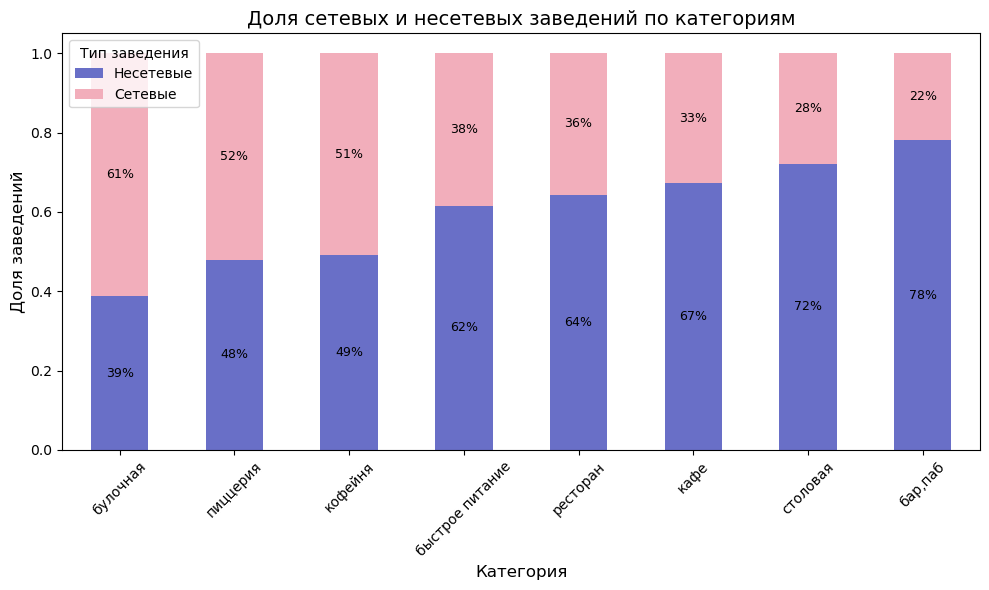

In [35]:
# Нормализуем, чтобы получить долю, а не количество
category_chain_norm = category_chain.div(category_chain.sum(axis=1), axis=0)

# Добавим сортировку по доле сетевых заведений
category_chain_norm = category_chain_norm.sort_values(by='Сетевые', ascending=False)

# Строим стековую диаграмму
ax = category_chain_norm.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    color=['#696FC7','#F2AEBB']
)

# Подписи и оформление
plt.title('Доля сетевых и несетевых заведений по категориям', fontsize=14)
plt.xlabel('Категория', fontsize=12)
plt.ylabel('Доля заведений', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Тип заведения', loc='best')
plt.tight_layout()

# Добавим подписи процентов на столбцы
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    ax.text(x + width / 2, y + height / 2,
            f'{height:.0%}',
            ha='center', va='center', fontsize=9, color='black')


plt.show()


Общее соотношение сетевых и несетевых заведений:
Несетевых заведений больше — 5199 против 3203 сетевых, то есть большинство заведений Москвы остаются независимыми.

По категориям:

- В таких категориях, как кофейни, пиццерии и булочные, количество сетевых и несетевых заведений примерно сопоставимо, разница незначительная.

- Кафе, рестораны и бары/пабы преимущественно несетевые.

- Столовые почти полностью несетевые.

Таким образом, независимые заведения доминируют на рынке, а сети чаще встречаются в специфических категориях вроде кофеен и булочных, но и там незначительно превышают несетевые по количеству

---

### Задача 4

- Анализируем распределение посадочных мест в заведениях общественного питания. Исследуем данные на наличие аномальных значений и выбросов, которые могут быть связаны с особенностями форматов заведений или ошибками в данных.
- Для каждой категории определим наиболее типичное количество мест, используя подходящие визуализации — ящики с усами для выявления выбросов и столбчая диаграмма для анализа распределений.


Сначала посмотрим на базовую статистику по столбцу `seats`:

In [36]:
# Отбираем только заведения с корректным количеством мест
seats_real = rest_df[rest_df['seats'] != -1]['seats']

# Базовая статистика без -1
seats_real.describe()

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

Визуализируем распределение через boxplot:

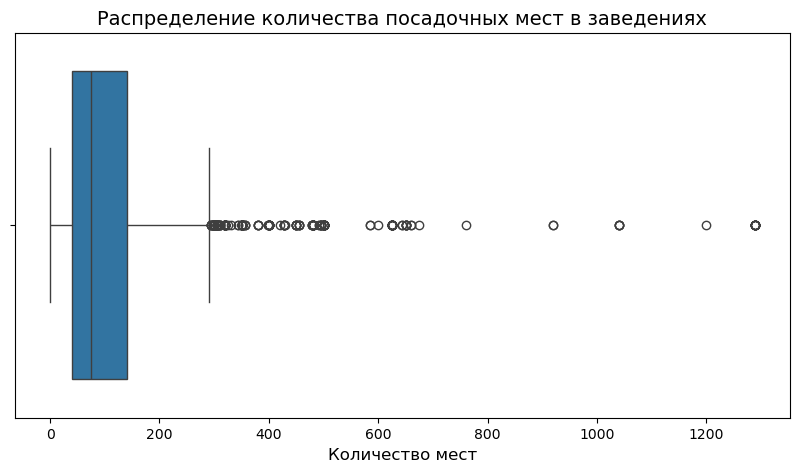

In [37]:
plt.figure(figsize=(10,5))
sns.boxplot(x=seats_real)
plt.title('Распределение количества посадочных мест в заведениях', fontsize=14)
plt.xlabel('Количество мест', fontsize=12)
plt.show()


Считаем медиану по каждой категории:

In [38]:
seats_by_category = rest_df[rest_df['seats'] != -1].groupby('category')['seats'].median().sort_values(ascending=False)
print(seats_by_category)

category
ресторан           86.0
бар,паб            82.0
кофейня            80.0
столовая           75.5
быстрое питание    65.0
кафе               60.0
пиццерия           55.0
булочная           50.0
Name: seats, dtype: float64


Визуализируем горизонтальной столбчатой диаграммой:

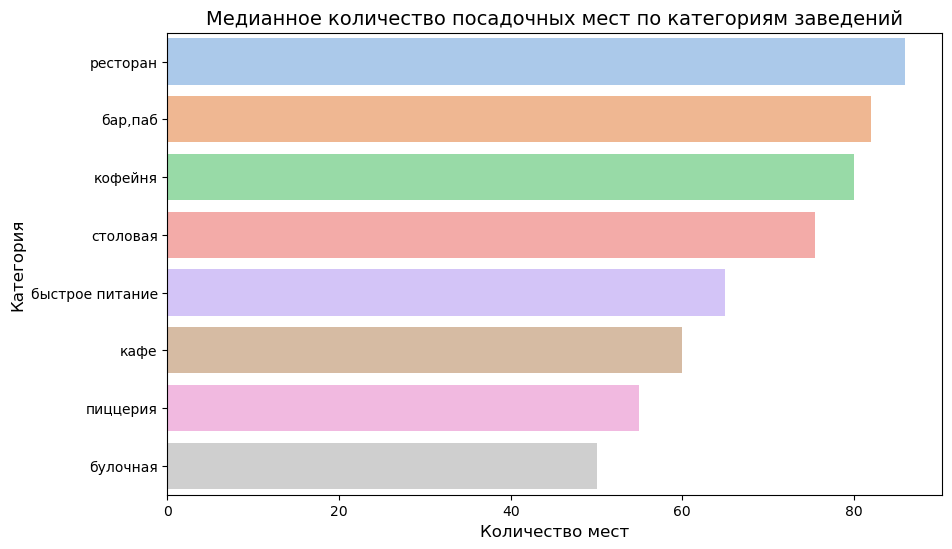

In [39]:
plt.figure(figsize=(10,6))
sns.barplot(x=seats_by_category.values, y=seats_by_category.index, palette='pastel')
plt.title('Медианное количество посадочных мест по категориям заведений', fontsize=14)
plt.xlabel('Количество мест', fontsize=12)
plt.ylabel('Категория', fontsize=12)
plt.show()

- Анализ вместимости заведений показывает разнообразие размеров. Базовая статистика демонстрирует минимальные 50 мест, максимальные 86 и среднее около 70–75 мест.

- Нижняя граница почти совпадает с минимальным значением — значит маленьких заведений с аномально низкой вместимостью нет.
Верхняя граница немного выше 86, а сверху есть несколько точек-выбросов — это крупные заведения, которые значительно больше остальных.
Ящик показывает, что большая часть заведений находится примерно между 60 и 80 местами.
Медиана около 70–75 мест, что совпадает с общей картиной.

- Распределение медиан по категориям уточняет картину: рестораны, бары и кофейни имеют наибольшую среднюю вместимость (80–86 мест), тогда как булочные и пиццерии — наименьшую (50–55 мест). В целом, выбор формата заведения сильно влияет на размер, но даже внутри одного типа встречаются более крупные точки.

---

### Задача 5

- Исследуем распределение рейтингов заведений общественного питания по категориям. Проанализируем, насколько значительно различаются средние оценки посетителей для разных типов заведений — ресторанов, кафе, баров и других форматов.
- Для наглядного сравнения построим визуализацию, которая покажет диапазоны и средние значения рейтингов в разрезе категорий, что позволит выявить наиболее и наименее успешные в оценках гостей форматы заведений.

In [40]:
# Основные статистики по всем рейтингам
ratings_stats = rest_df['rating'].describe()
print(ratings_stats)

count    8402.000000
mean        4.230016
std         0.470318
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64


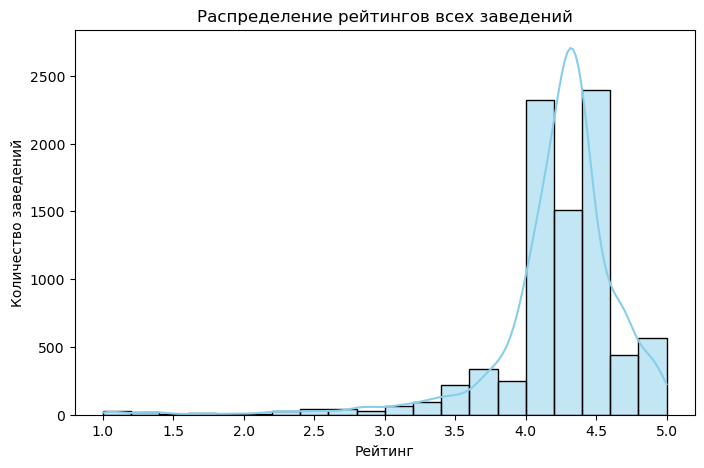

In [41]:
plt.figure(figsize=(8,5))
sns.histplot(rest_df['rating'], bins=20, kde=True, color='skyblue')
plt.title('Распределение рейтингов всех заведений')
plt.xlabel('Рейтинг')
plt.ylabel('Количество заведений')
plt.show()

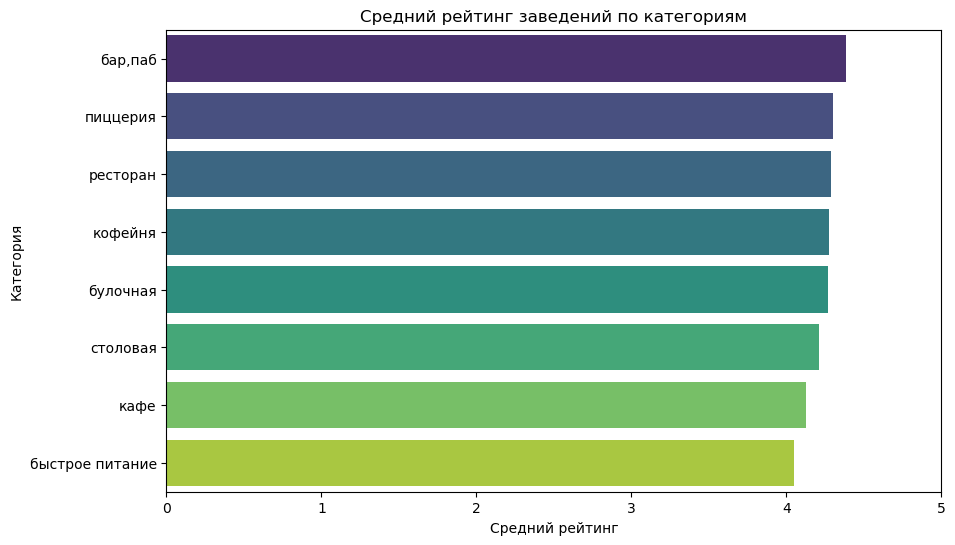

In [42]:
avg_rating_by_category = rest_df.groupby('category')['rating'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=avg_rating_by_category.values, y=avg_rating_by_category.index, palette='viridis')
plt.title('Средний рейтинг заведений по категориям')
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория')
plt.xlim(0,5)
plt.show()

- Рейтинги сконцентрированы вокруг среднего, большая часть заведений имеет рейтинг от 4 до 4.5. Сильно низких или высоких оценок немного, что и подтверждает относительно небольшое стандартное отклонение = 0.47. График распределения имеет левый хвост, что подтверждает базовую статистику. Наибольшая вероятность встретить рейтинг ~ 4,4.
- Усреднённые рейтинги различных типов заведений отличаются незначительно: бары и пабы в среднем оцениваются немного выше, фастфуд — немного ниже, но большинство категорий сосредоточено в диапазоне 4.0–4.3, что говорит о том, что клиенты оценивают все типы общепита примерно одинаково, с небольшими отклонениями.


---

### Задача 6

- Проанализируем взаимосвязи между рейтингом заведений и различными параметрами: категорией, районом расположения, сетевым статусом, количеством посадочных мест, ценовой категорией и круглосуточным режимом работы.
- Построим матрицу корреляции для выявления наиболее сильных статистических связей.
- После идентификации ключевой зависимости детально проверим её надежность и интерпретируем практический смысл этой взаимосвязи.



In [43]:
# Вычисляем корреляционную матрицу с использованием phi_k
correlation_matrix = rest_df[['category', 'district', 'chain', 'seats', 'price', 'is_24_7', 'rating']].phik_matrix()

# Выводим результат
print('Корреляционная матрица с коэффициентом phi_k для переменной rating')
correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)


interval columns not set, guessing: ['chain', 'seats', 'rating']
Корреляционная матрица с коэффициентом phi_k для переменной rating


,rating
price,0.262056
category,0.198739
district,0.189453
is_24_7,0.161010
chain,0.118857
seats,0.000000


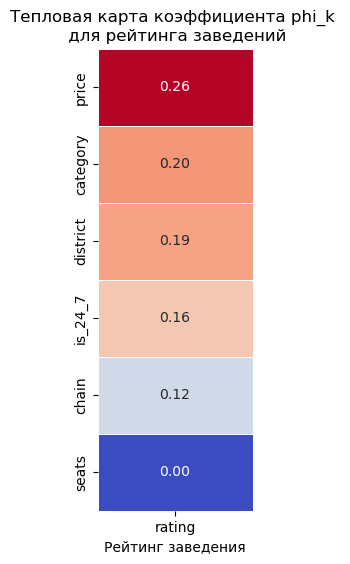

In [44]:
# Строим тепловую карту
plt.figure(figsize=(2, 6))

# Сохраняем матрицу корреляции рейтинга с другими признаками
data_heatmap = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)

sns.heatmap(data_heatmap,
            annot=True,       # Отображаем численные значения
            fmt='.2f',        # Два знака после точки
            cmap='coolwarm',  # Цветовая гамма
            linewidths=0.5,   # Линии между ячейками
            cbar=False        # Без цветовой шкалы
           )

# Заголовок и подпись оси X
plt.title('Тепловая карта коэффициента phi_k \n для рейтинга заведений')
plt.xlabel('Рейтинг заведения')

# Выводим график
plt.show()

- Самая сильная связь у `rating` с `price`. Сделаем сводную таблицу, чтобы посмотреть, как средний рейтинг распределяется по ценовым категориям:

In [45]:
rest_df.groupby('price')['rating'].mean().sort_values(ascending=False)


price
высокие          4.436611
выше среднего    4.386347
средние          4.297874
низкие           4.173077
Name: rating, dtype: float32

- Добавим диаграмму boxplot — она наглядно покажет, как распределяются рейтинги в разных ценовых категориях и позволит быстро оценить различия между ними. 

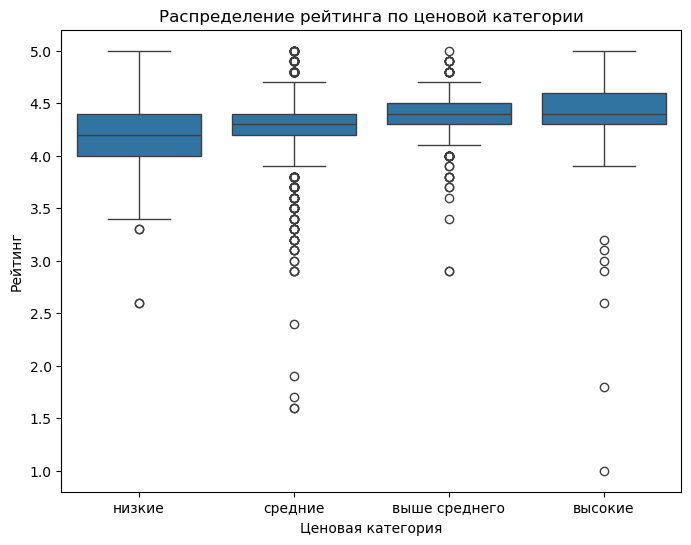

In [46]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='price', y='rating', data=rest_df, order=['низкие', 'средние', 'выше среднего', 'высокие'])
plt.title('Распределение рейтинга по ценовой категории')
plt.xlabel('Ценовая категория')
plt.ylabel('Рейтинг')
plt.show()


- На основе анализа корреляции рейтинг заведений демонстрирует слабую положительную связь с ценовой категорией — чем выше ценовой сегмент, тем несколько выше оценки. Категория заведения и район расположения также оказывают умеренное влияние на рейтинг. При этом такие факторы, как сетевой статус и круглосуточный режим работы, показывают минимальную корреляцию, а количество посадочных мест практически не связано с оценками посетителей. Наиболее существенная, хотя и слабая, зависимость наблюдается между рейтингом и ценовой политикой заведения.

Тренд зависимости рейтинга от цены: 

- Видно чёткое положительное направление: чем выше ценовая категория заведения, тем выше средний рейтинг. Это может означать, что клиенты оценивают качество выше в более дорогих заведениях или что более дорогие заведения чаще предоставляют лучший сервис, атмосферу или еду.

- Из графика видно, что заведения с более высокой ценовой категорией чаще имеют более высокий рейтинг, чем заведения с низкой ценовой категорией. Медиана рейтинга растёт от «низких» к «высоким» ценовым категориям. Также видно, что разброс оценок в более дорогих категориях меньше: это говорит о большей стабильности высокого рейтинга среди дорогих заведений.

Вывод
- График подтверждает: рестораны с более высокой ценой, как правило, получают более высокие рейтинги по сравнению с заведениями с низкой ценовой категорией.

---

### Задача 7

- Проанализируем популярные сетевые заведения Москвы, сгруппировав данные по названиям сетей и выделив топ-15 по количеству заведений в регионе. Для каждой сети рассчитаем средний рейтинг и определим их основную категорию.
- Результаты представим в виде наглядной визуализации, показывающей одновременно размер сети и среднюю оценку посетителей, что позволит выявить наиболее успешные и распространенные сетевые форматы в столице.

In [47]:
# Группируем по названию сети
top_chains = (
    rest_df.groupby('name')
    .agg(
        count=('name', 'count'),          # Количество заведений сети
        mean_rating=('rating', 'mean'),  # Средний рейтинг сети
        category=('category', 'first')   # Категория сети (берем первую попавшуюся)
    )
    .sort_values(by='count', ascending=False)  # Сортируем по популярности
    .head(15)  # Берем топ-15
)

top_chains

,count,mean_rating,category
name,,,
кафе,188,3.884574,кафе
шоколадница,120,4.177500,кофейня
домино'с пицца,77,4.171428,пиццерия
додо пицца,74,4.286487,пиццерия
one price coffee,72,4.069445,кофейня
яндекс лавка,69,3.872464,ресторан
cofix,65,4.075385,кофейня
prime,50,4.116000,ресторан
хинкальная,44,4.322727,быстрое питание


In [48]:
# 1) Отфильтруем только сетевые заведения
chains_only = rest_df[rest_df['chain'] == 1].copy()

# 2) Группируем по названию сети и выбираем топ-15 по числу точек
top_chains = (
    chains_only.groupby('name', as_index=True)
    .agg(
        count=('name', 'size'),          # число заведений сети
        mean_rating=('rating', 'mean'),  # средний рейтинг
        category=('category', 'first')   # категория — первая встречающаяся
    )
    .sort_values(by='count', ascending=False)
    .head(15)
)

# Посмотрим таблицу
display(top_chains)


,count,mean_rating,category
name,,,
шоколадница,120,4.177500,кофейня
домино'с пицца,76,4.169737,пиццерия
додо пицца,74,4.286487,пиццерия
one price coffee,71,4.064789,кофейня
яндекс лавка,69,3.872464,ресторан
cofix,65,4.075385,кофейня
prime,50,4.116000,ресторан
хинкальная,44,4.322727,быстрое питание
кофепорт,42,4.147619,кофейня


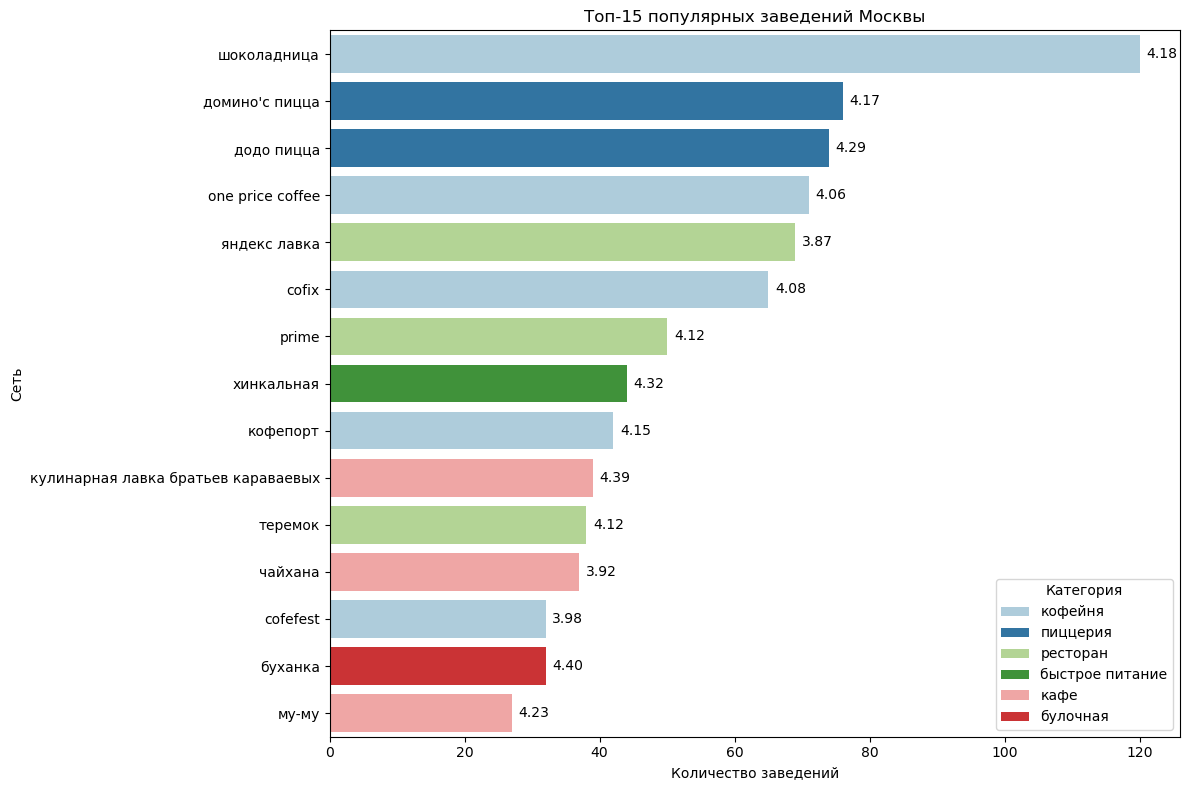

In [49]:
plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_chains,
    y=top_chains.index,
    x='count',
    hue='category',
    dodge=False,
    palette="Paired"
)

for i, (count, rating) in enumerate(zip(top_chains['count'], top_chains['mean_rating'])):
    plt.text(count + 1, i, f"{rating:.2f}", va='center')

plt.xlabel('Количество заведений')
plt.ylabel('Сеть')
plt.title('Топ-15 популярных заведений Москвы')
plt.legend(title='Категория')
plt.tight_layout()
plt.show()

- Самые многочисленные сети Москвы — это кофейни и пиццерии.
Абсолютный лидер — «Шоколадница» (120 заведений, средний рейтинг 4.18), за ней следуют «Домино’с пицца» (76 точек, 4.17), «Додо пицца» (74, 4.29) и «One Price Coffee» (71, 4.06). Эти бренды формируют основной массив массового рынка кофеен и пиццерий.

- Рестораны и заведения с более высокой кухней встречаются реже, но отличаются стабильным качеством:
например, «Prime» (4.12), «Теремок» (4.12) и «Яндекс Лавка» (3.87) демонстрируют уверенные показатели при умеренном числе точек.

- Среди заведений быстрого питания и кафе выделяются сети с наиболее высокими пользовательскими оценками:
«Хинкальная» (4.32), «Кулинарная лавка братьев Караваевых» (4.39) и «Буханка» (4.40) — это самые высоко оценённые бренды из топ-15. Они уступают лидерам по числу филиалов, но заметно выигрывают по уровню качества и восприятию клиентами.

- В целом наблюдается обратная зависимость между масштабом сети и средней оценкой:
крупные и массовые бренды чаще получают средние рейтинги (около 4.0–4.2), тогда как небольшие сети и специализированные форматы демонстрируют оценки выше 4.3.

---

### Задача 8

- Исследуем вариацию среднего чека заведений в разрезе административных округов Москвы с особым вниманием к Центральному административному округу (ЦАО). При этом учитываем, что средний чек может быть искажен выбросами, поэтому дополнительно рассматриваем медиану, которая более устойчиво отражает типичную ценовую политику заведений.

- Для наглядного сравнения построим визуализацию, где средний и медианный чеки будут показаны рядом для каждого округа. Это позволит сразу увидеть районы с высокими ценами и влияние выбросов на среднее значение.

- Также создадим таблицу с двойной разбивкой по округам и типам заведений, с градиентным выделением, чтобы легко было сравнивать ценовую политику разных категорий заведений по районам.

In [50]:
district_stats = rest_df.groupby('district', as_index=False)['middle_avg_bill'].agg(['mean','median']).reset_index()
district_stats = district_stats.sort_values('median', ascending=False)
print(district_stats)


   index                                 district         mean  median
1      1          Западный административный округ  1053.225490  1000.0
5      5       Центральный административный округ  1191.057547  1000.0
4      4   Северо-Западный административный округ   822.222930   700.0
2      2          Северный административный округ   927.959627   650.0
7      7      Юго-Западный административный округ   792.561702   600.0
0      0         Восточный административный округ   820.626923   575.0
3      3  Северо-Восточный административный округ   716.611296   500.0
8      8             Южный административный округ   834.398089   500.0
6      6     Юго-Восточный административный округ   654.097938   450.0


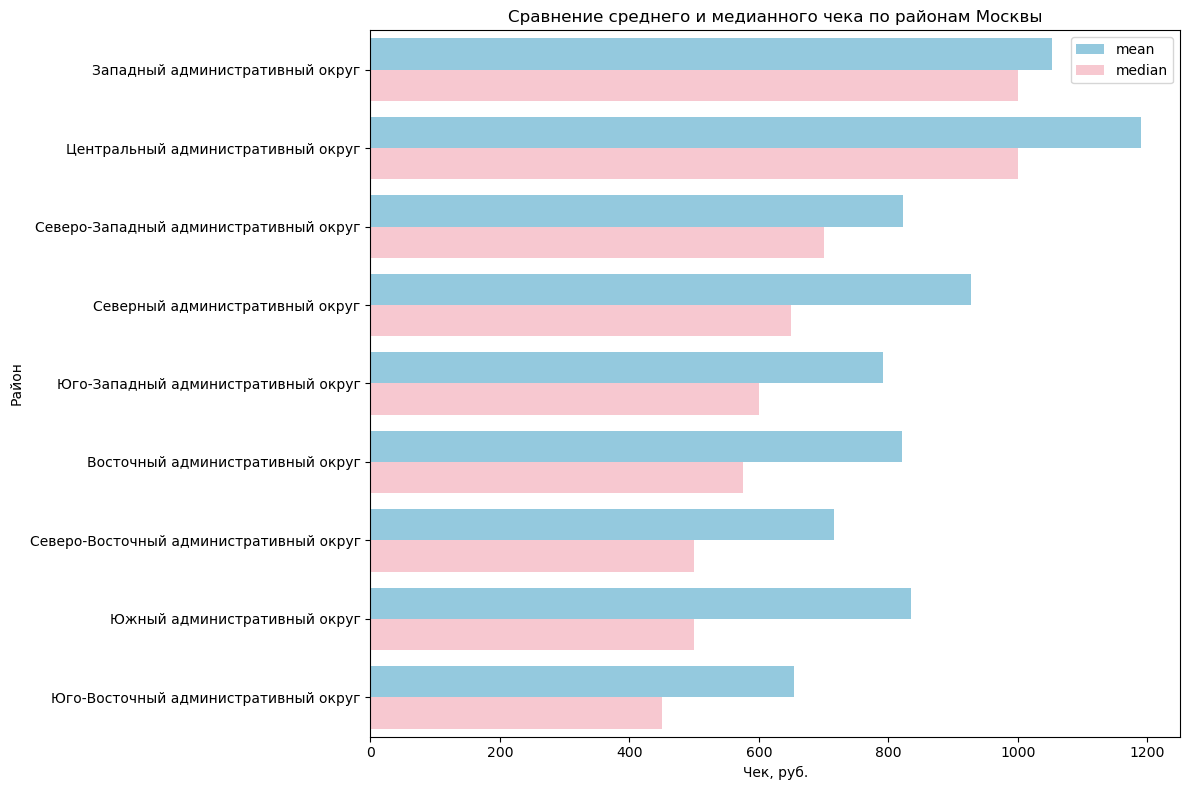

In [51]:
# Группировка: среднее и медиана
district_stats = rest_df.groupby('district', as_index=False)['middle_avg_bill'].agg(['mean','median']).reset_index()
district_stats = district_stats.sort_values('median', ascending=False)

# Переводим данные в "длинный" формат для sns.barplot
district_long = district_stats.melt(id_vars='district', value_vars=['mean','median'], 
                                    var_name='Metric', value_name='Bill')

plt.figure(figsize=(12,8))
sns.barplot(
    data=district_long,
    y='district',
    x='Bill',
    hue='Metric',   # разделяем среднее и медиану цветом
    palette=['skyblue', 'pink']
)

plt.xlabel('Чек, руб.')
plt.ylabel('Район')
plt.title('Сравнение среднего и медианного чека по районам Москвы')
plt.legend(title='')
plt.tight_layout()
plt.show()


In [52]:
# pivot table по районам и типам заведений
pivot = rest_df.pivot_table(
    index='district',
    columns='category',
    values='middle_avg_bill',
    aggfunc='median'
)

# применяем Styler с округлением до 1 знака
pivot.style.format("{:.1f}").background_gradient(cmap='coolwarm', axis=1)


category,"бар,паб",булочная,быстрое питание,кафе,кофейня,пиццерия,ресторан,столовая
district,,,,,,,,
Восточный административный округ,1200.0,300.0,375.0,450.0,400.0,500.0,1000.0,300.0
Западный административный округ,1250.0,600.0,367.5,625.0,600.0,700.0,1300.0,300.0
Северный административный округ,1250.0,625.0,300.0,550.0,325.0,650.0,1187.5,300.0
Северо-Восточный административный округ,900.0,500.0,425.0,475.0,325.0,500.0,837.5,275.0
Северо-Западный административный округ,1000.0,200.0,275.0,650.0,325.0,549.5,1250.0,300.0
Центральный административный округ,1250.0,962.5,450.0,700.0,500.0,1000.0,1250.0,300.0
Юго-Восточный административный округ,925.0,375.0,300.0,400.0,250.0,500.0,925.0,275.0
Юго-Западный административный округ,1000.0,500.0,375.0,450.0,375.0,500.0,1050.0,305.0
Южный административный округ,1175.0,437.5,400.0,600.0,387.5,500.0,975.0,282.5


- Центральный административный округ (ЦАО) сохраняет лидерство по среднему чеку — среднее значение составляет ≈1191 ₽, медиана — 1000 ₽. Это подтверждает, что заведения здесь дороже остальных районов, что связано с более высоким уровнем жизни, концентрацией бизнес-центров и туристической активности.

- Западный административный округ демонстрирует почти такой же высокий средний чек (≈1053 ₽, медиана 1000 ₽), а Северный и Северо-Западный округа также показывают значимые показатели (среднее 928–822 ₽, медиана 650–700 ₽). Эти районы характеризуются престижной локацией и наличием премиальных заведений.

- Юго-Западный, Восточный и Южный округа имеют средние чеки в диапазоне 792–834 ₽, медиана 500–600 ₽, что говорит о более умеренной ценовой политике.

- На периферии, в частности в Юго-Восточном и Северо-Восточном округах, средний чек снижается до 654–717 ₽, медиана — 450–500 ₽. Это отражает более низкие арендные ставки, меньшую покупательную способность и ориентацию бизнеса на массового потребителя.

- В таблице с двойной разбивкой по округам и категориям видно, что самые дорогие рестораны и бары сосредоточены в ЦАО и Западном округе, тогда как кафе, кофейни и пиццерии более равномерно распределены по городским районам.

- Диаграмма с рядом стоящими средним и медианным чеками визуально подтверждает тенденцию: чем ближе к центру, тем выше стоимость посещения, а периферийные округа демонстрируют более низкие показатели.

- Эти различия важно учитывать при анализе рынка, планировании маркетинговых стратегий и открытии новых заведений, чтобы соответствовать ценовым ожиданиям клиентов в разных районах Москвы.


---

### Промежуточный вывод


В ходе исследовательского анализа данных о заведениях общественного питания Москвы были выявлены следующие ключевые моменты:

1. Распределение заведений по категориям: Наибольшее количество заведений приходится на кафе (2376), рестораны (2042) и кофейни (1413). Это говорит о том, что рынок общественного питания Москвы ориентирован на эти категории. Менее представлены бары/пабы (764), пиццерии (633), быстрое питание (603), столовые (315) и булочные (256).

2. Распределение заведений по административным округам: Центральный административный округ лидирует по количеству заведений (2242), что свидетельствует о его высокой концентрации и привлекательности для открытия новых точек. Наименьшее количество заведений находится в Северо-Западном административном округе (409).

3. Особенности Центрального административного округа: В ЦАО также преобладают кафе, рестораны и кофейни, что подтверждает общую тенденцию по городу. Однако здесь наблюдается более высокая плотность заведений, что может указывать на насыщенность рынка и высокую конкуренцию.

4. Круглосуточные заведения: В Москве насчитывается 772 заведения, работающих круглосуточно. Это важный фактор для выбора формата заведения, особенно в центральных районах с высоким трафиком.

5. Пропуски в данных: Наибольшее количество пропусков наблюдается в столбцах, связанных с ценами (от 55% до 93%), что ограничивает возможность детального анализа ценовой политики. Однако это не помешало выявить общие тенденции.

6. Сетевые заведения: В данных присутствуют как сетевые, так и независимые заведения. Анализ их распределения может помочь в выборе стратегии для нового заведения.


## Итоговый вывод и рекомендации

### Общий обзор
Был проведен исследовательский анализ данных о заведениях общественного питания Москвы, включая их категории, распределение по административным округам, режим работы, рейтинги и другие характеристики. Данные были предобработаны: объединены, обработаны пропуски, удалены дубликаты, создан новый признак is_24_7. Визуализации помогли выявить ключевые тенденции и закономерности.


### Главные выводы
1. **Категории заведений:** На рынке доминируют кафе, рестораны и кофейни. Это наиболее востребованные форматы среди москвичей и гостей города.
2. **Географическое распределение:** Центральный административный округ является самым насыщенным заведениями, что указывает на высокую конкуренцию, но также и на высокий спрос. Наименее представлены заведения в Северо-Западном округе.
3. **Круглосуточные заведения:** Их количество (772) показывает, что этот формат востребован, особенно в центральных районах.
4. **Ценовая политика:** Из-за большого количества пропусков в данных о ценах сложно сделать точные выводы, однако можно предположить, что средний и выше среднего ценовые сегменты наиболее распространены. 

### Рекомендации для заказчика
1. **Выбор категории:** Для минимизации рисков стоит рассмотреть форматы, пользующиеся стабильным спросом: кафе, рестораны или кофейны. Однако для уменьшения конкуренции можно обратить внимание на менее представленные категории, такие как столовые или булочные, особенно если они будут ориентированы на уникальную концепцию.

2. **Выбор локации:**

- Центральный округ: Подходит для премиальных или сетевых заведений, ориентированных на высокий трафик. Однако здесь высокая конкуренция и арендные ставки.

- Северо-Западный округ: Менее насыщен заведениями, что может предоставить возможности для роста. Рекомендуется рассмотреть открытие заведения в этом районе.

3. **Режим работы:** Круглосуточный формат может быть выгоден в центральных районах с высоким ночным трафиком. Однако он требует дополнительных ресурсов и персонала.

4. **Ценовая стратегия:** Рекомендуется ориентироваться на средний ценовой сегмент, так как он наиболее распространен и пользуется спросом у широкой аудитории.

5. **Уникальность:** Для успешного запуска важно предложить уникальную концепцию, например, сочетание кофейни и коворкинга или ресторана с тематическими вечерами. Это поможет выделиться на фоне конкурентов.



В целом, рынок общественного питания Москвы динамичен и разнообразен. Успех нового заведения будет зависеть от тщательного выбора локации, формата и ценовой политики, а также от умения предложить уникальный опыт для посетителей.